### Simple Chains

In [9]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv

load_dotenv()

prompt = PromptTemplate(
    template = "give top 5 cricters in {topic} departments, just the list",
    input_variables=['topic']
)
model = ChatGroq(model = "openai/gpt-oss-120b")
parser = StrOutputParser()
chains = prompt |model | parser

result = chains.invoke({"topic" : "pace attack"})

print(result)




1. Jasprit Bumrah (India)  
2. Pat Cummins (Australia)  
3. Kagiso Rabada (South Africa)  
4. Trent Boult (New Zealand)  
5. Shaheen Shah Afridi (Pakistan)


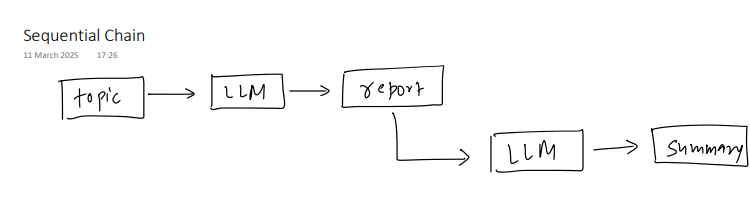

In [11]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

load_dotenv()

prompt1 = PromptTemplate(
    template='Generate a detailed report on {topic}',
    input_variables=['topic']
)

prompt2 = PromptTemplate(
    template='Generate a 5 pointer summary from the following text \n {text}',
    input_variables=['text']
)

model = ChatGroq(model = "openai/gpt-oss-120b")

parser = StrOutputParser()

chain = prompt1 | model | parser | prompt2 | model | parser

result = chain.invoke({'topic': 'technologies of india to the world'})

print(result)



**5‑Point Summary – India’s Technology Landscape (2025‑2026)**  

1. **Global Tech Powerhouse** – India now ranks 2nd in IT services revenue (US $230 bn) and 3rd in commercial space launches (112 missions), with a rapidly expanding footprint in software products, renewables, biotech, and fintech.  

2. **Talent & Cost Advantage** – Over 2 million engineering graduates are produced each year, delivering world‑class R&D at 40‑60 % lower cost than Western peers, fueling a vibrant startup ecosystem valued at US $150 bn and supporting 9,800+ tech‑focused startups.  

3. **Strategic Government Programs** – Initiatives such as Digital India, Make in India, Production‑Linked Incentive (PLI) schemes, and the Space India 2025 roadmap underpin growth, targeting a 2 % R&D intensity of GDP by 2030 and a US $100 bn electronics manufacturing turnover by 2030.  

4. **Sector Highlights** –  
   - **IT Services:** 55 % of global outsourced development, 30 % of worldwide IT consulting revenue.  
   - **

### Parallel chain

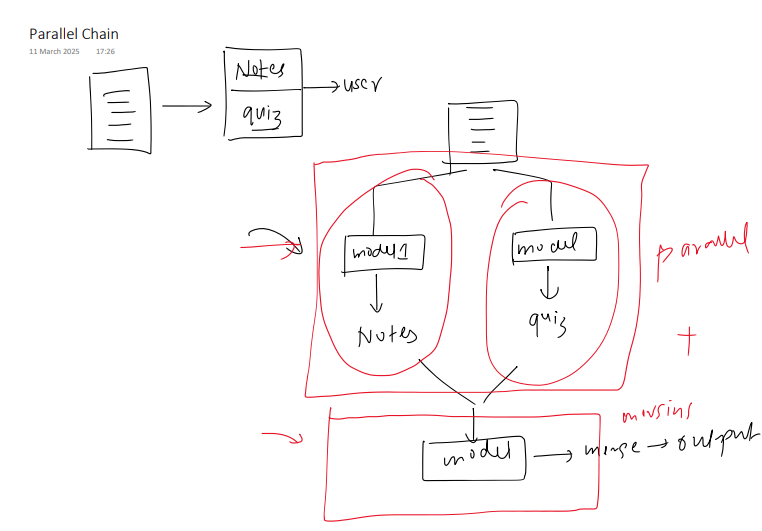

In [13]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel

load_dotenv()

model = ChatGroq(model = "openai/gpt-oss-120b")


prompt1 = PromptTemplate(
    template='Generate short and simple notes from the following text \n {text}',
    input_variables=['text']
)

prompt2 = PromptTemplate(
    template='Generate 5 short question answers from the following text \n {text}',
    input_variables=['text']
)

prompt3 = PromptTemplate(
    template='Merge the provided notes and quiz into a single document \n notes -> {notes} and quiz -> {quiz}',
    input_variables=['notes', 'quiz']
)

parser = StrOutputParser()

parallel_chain = RunnableParallel({
    'notes': prompt1 | model | parser,
    'quiz': prompt2 | model | parser
})

merge_chain = prompt3 | model | parser

chain = parallel_chain | merge_chain

text = """
Support vector machines (SVMs) are a set of supervised learning methods used for classification, regression and outliers detection.

The advantages of support vector machines are:

Effective in high dimensional spaces.

Still effective in cases where number of dimensions is greater than the number of samples.

Uses a subset of training points in the decision function (called support vectors), so it is also memory efficient.

Versatile: different Kernel functions can be specified for the decision function. Common kernels are provided, but it is also possible to specify custom kernels.

The disadvantages of support vector machines include:

If the number of features is much greater than the number of samples, avoid over-fitting in choosing Kernel functions and regularization term is crucial.

SVMs do not directly provide probability estimates, these are calculated using an expensive five-fold cross-validation (see Scores and probabilities, below).

The support vector machines in scikit-learn support both dense (numpy.ndarray and convertible to that by numpy.asarray) and sparse (any scipy.sparse) sample vectors as input. However, to use an SVM to make predictions for sparse data, it must have been fit on such data. For optimal performance, use C-ordered numpy.ndarray (dense) or scipy.sparse.csr_matrix (sparse) with dtype=float64.
"""

result = chain.invoke({'text':text})

print(result)



**Support Vector Machines (SVMs) – Quick Reference & Quiz**

---

### 1. What SVMs Are  
- **Supervised learning methods** used for **classification**, **regression**, and **outlier detection**.

---

### 2. Key Advantages  

| Advantage | Why It Matters |
|-----------|----------------|
| **Works well in high‑dimensional spaces** | Handles many features without a performance drop. |
| **Effective when features > samples** | Still learns useful decision boundaries even with few examples. |
| **Memory‑efficient** | Only a **subset of training points** (the *support vectors*) are needed for the decision function. |
| **Versatile kernels** | Built‑in kernels (linear, poly, RBF, sigmoid) or custom kernels can be used to capture complex relationships. |

---

### 3. Main Disadvantages  

| Disadvantage | Mitigation |
|--------------|------------|
| **Risk of over‑fitting** when **features far exceed samples** | Choose an appropriate kernel, tune the regularization parameter **C**, and consid

### Condn Chain
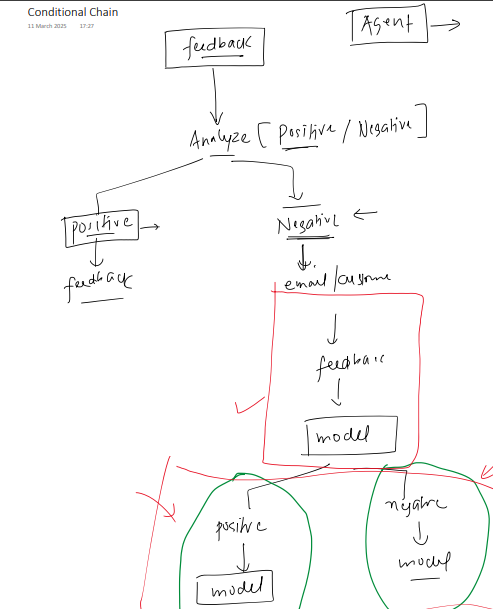

In [17]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnableBranch, RunnableLambda
from langchain_core.output_parsers import PydanticOutputParser
from pydantic import BaseModel, Field
from typing import Literal

load_dotenv()

model = ChatGroq(model = "openai/gpt-oss-120b")

parser = StrOutputParser()

class Feedback(BaseModel):

    sentiment: Literal['positive', 'negative'] = Field(description='Give the sentiment of the feedback')

parser2 = PydanticOutputParser(pydantic_object=Feedback)

prompt1 = PromptTemplate(
    template='Classify the sentiment of the following feedback text into postive or negative \n {feedback} \n {format_instruction}',
    input_variables=['feedback'],
    partial_variables={'format_instruction':parser2.get_format_instructions()}
)

classifier_chain = prompt1 | model | parser2

prompt2 = PromptTemplate(
    template='Write an appropriate response to this positive feedback \n {feedback}',
    input_variables=['feedback']
)

prompt3 = PromptTemplate(
    template='Write an appropriate response to this negative feedback \n {feedback}',
    input_variables=['feedback']
)

branch_chain = RunnableBranch(
    (lambda x:x.sentiment == 'positive', prompt2 | model | parser),
    (lambda x:x.sentiment == 'negative', prompt3 | model | parser),
    RunnableLambda(lambda x: "could not find sentiment")
)

chain = classifier_chain | branch_chain

print(chain.invoke({'feedback': 'This is a beautiful phone'}))


Thank you so much for your kind words! We’re thrilled to hear that you had a positive experience, and we truly appreciate you taking the time to let us know. Your feedback motivates our team to keep delivering the best possible service/product, and it’s wonderful to know our efforts are making a difference. If there’s anything else we can do for you, please don’t hesitate to reach out. Thanks again for your support!
